In [1]:
# Step 1: Load MNIST Data
from tensorflow.keras.datasets import mnist
import matplotlib.pyplot as plt
import numpy as np

# Load dataset
(x_train, y_train), (x_test, y_test) = mnist.load_data()

# Display dataset shape
print(f"Training data shape: {x_train.shape}, Training labels shape: {y_train.shape}")
print(f"Test data shape: {x_test.shape}, Test labels shape: {y_test.shape}")


2025-07-24 10:33:32.360449: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:477] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1753353212.613585      36 cuda_dnn.cc:8310] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1753353212.679799      36 cuda_blas.cc:1418] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered


11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
Training data shape: (60000, 28, 28), Training labels shape: (60000,)
Test data shape: (10000, 28, 28), Test labels shape: (10000,)


# 🧠 MNIST Digit Classifier

Welcome to the MNIST digit classification notebook!  
In this notebook, we'll build a high-performance digit recognizer using deep learning techniques with GPU acceleration. Let's begin by exploring the dataset.

---

## 🔍 Step 1: Load and Explore the MNIST Dataset

We load the MNIST dataset using TensorFlow's built-in API. MNIST consists of 60,000 training and 10,000 test grayscale images of handwritten digits (0–9), each 28x28 pixels in size.


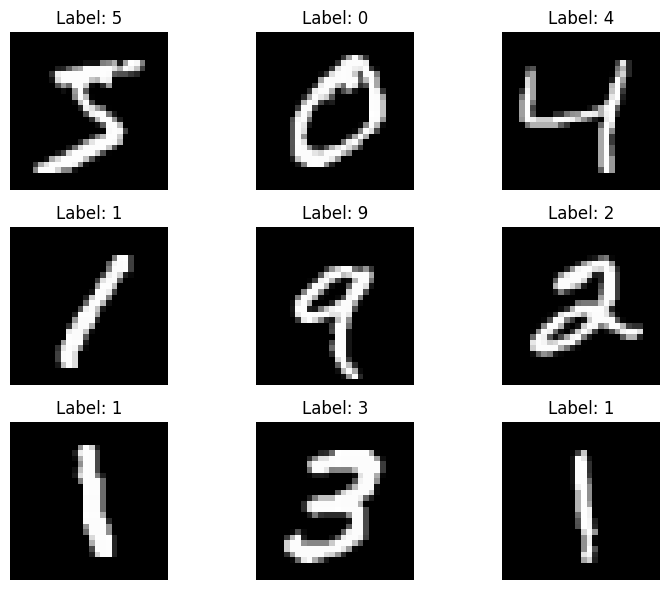

In [2]:
# Show 9 sample images
plt.figure(figsize=(8, 6))
for i in range(9):
    plt.subplot(3, 3, i+1)
    plt.imshow(x_train[i], cmap='gray')
    plt.title(f"Label: {y_train[i]}")
    plt.axis('off')
plt.tight_layout()
plt.show()


## 🖼️ Step 2: Visualize Sample Digits

Let's visualize some training examples to understand the task better.


In [3]:
# Normalize images to [0, 1]
x_train = x_train.astype('float32') / 255.0
x_test = x_test.astype('float32') / 255.0

# Reshape to (28, 28, 1) for CNN
x_train = np.expand_dims(x_train, -1)
x_test = np.expand_dims(x_test, -1)

# One-hot encode labels
from tensorflow.keras.utils import to_categorical
y_train_cat = to_categorical(y_train, 10)
y_test_cat = to_categorical(y_test, 10)


## 🧹 Step 3: Preprocessing

We normalize the pixel values to range [0, 1] and reshape the data to (28x28x1) for CNN input. Labels are one-hot encoded.


In [4]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout

model = Sequential([
    Conv2D(32, (3, 3), activation='relu', input_shape=(28, 28, 1)),
    MaxPooling2D(2, 2),
    
    Conv2D(64, (3, 3), activation='relu'),
    MaxPooling2D(2, 2),
    
    Flatten(),
    Dropout(0.4),
    Dense(128, activation='relu'),
    Dense(10, activation='softmax')
])

model.compile(optimizer='adam',
              loss='categorical_crossentropy',
              metrics=['accuracy'])

model.summary()


/usr/local/lib/python3.11/dist-packages/keras/src/layers/convolutional/base_conv.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)
I0000 00:00:1753353305.795815      36 gpu_device.cc:2022] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 15513 MB memory:  -> device: 0, name: Tesla P100-PCIE-16GB, pci bus id: 0000:00:04.0, compute capability: 6.0


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       204,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 225,034 (879.04 KB)

 Trainable params: 225,034 (879.04 KB)

 Non-trainable params: 0 (0.00 B)

## 🧠 Step 4: Build the CNN Model

A simple yet powerful convolutional neural network (CNN) is used to capture spatial hierarchies in the image data.


In [5]:
from tensorflow.keras.callbacks import EarlyStopping

early_stop = EarlyStopping(patience=3, restore_best_weights=True)

history = model.fit(x_train, y_train_cat,
                    epochs=10,
                    batch_size=128,
                    validation_split=0.1,
                    callbacks=[early_stop])


Epoch 1/10


I0000 00:00:1753353335.320913      99 service.cc:148] XLA service 0x7a0de8004cf0 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1753353335.321902      99 service.cc:156]   StreamExecutor device (0): Tesla P100-PCIE-16GB, Compute Capability 6.0
I0000 00:00:1753353335.604862      99 cuda_dnn.cc:529] Loaded cuDNN version 90300


 49/422 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.4899 - loss: 1.6257

I0000 00:00:1753353337.845446      99 device_compiler.h:188] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


422/422 ━━━━━━━━━━━━━━━━━━━━ 8s 9ms/step - accuracy: 0.8206 - loss: 0.5838 - val_accuracy: 0.9822 - val_loss: 0.0615
Epoch 2/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.9727 - loss: 0.0888 - val_accuracy: 0.9873 - val_loss: 0.0449
Epoch 3/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.9824 - loss: 0.0571 - val_accuracy: 0.9905 - val_loss: 0.0358
Epoch 4/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9866 - loss: 0.0427 - val_accuracy: 0.9895 - val_loss: 0.0414
Epoch 5/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9885 - loss: 0.0358 - val_accuracy: 0.9923 - val_loss: 0.0292
Epoch 6/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9913 - loss: 0.0296 - val_accuracy: 0.9922 - val_loss: 0.0299
Epoch 7/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9914 - loss: 0.0277 - val_accuracy: 0.9927 - val_loss: 0.0274
Epoch 8/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9927 - loss: 0.0229 - val_accuracy: 0.9923 - val_

## ⚡ Step 5: Train the Model (with GPU Acceleration)

We use EarlyStopping to avoid overfitting and make training efficient.


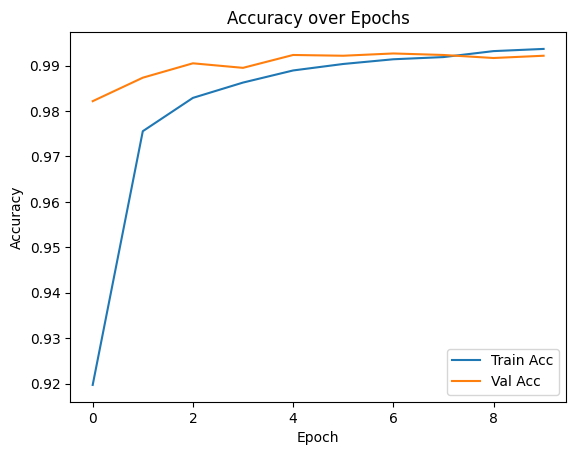

In [6]:
# Plot accuracy
plt.plot(history.history['accuracy'], label='Train Acc')
plt.plot(history.history['val_accuracy'], label='Val Acc')
plt.legend()
plt.title('Accuracy over Epochs')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.show()


## 📈 Step 6: Visualize Training Performance

Let's plot training and validation accuracy to understand model learning.


## 📊 Step 7: Evaluate on Test Set

We test our model on unseen MNIST test data to check generalization.


In [7]:
test_loss, test_acc = model.evaluate(x_test, y_test_cat)
print(f"Test Accuracy: {test_acc:.4f}")


313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9893 - loss: 0.0279
Test Accuracy: 0.9916


## 💾 Step 8: Save the Model

We save the model to reuse it for deployment or further evaluation.


In [8]:
# Save
model.save('mnist_cnn_model.h5')

# Load
# from tensorflow.keras.models import load_model
# model = load_model('mnist_cnn_model.h5')


## 🎮 Step 9: Make an Interactive Prediction

Pick a random test image and visualize the model's prediction.


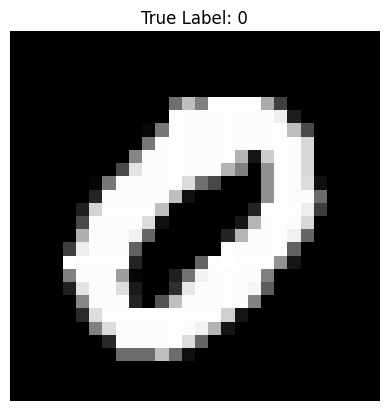

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 381ms/step
Predicted Label: 0


In [9]:
# Predict random sample
import random
i = random.randint(0, len(x_test)-1)
img = x_test[i]

plt.imshow(img.squeeze(), cmap='gray')
plt.title("True Label: {}".format(np.argmax(y_test_cat[i])))
plt.axis('off')
plt.show()

pred = model.predict(img.reshape(1, 28, 28, 1))
print(f"Predicted Label: {np.argmax(pred)}")


# ✅ Summary

- 📥 Loaded and explored MNIST data.
- 🧹 Preprocessed and normalized inputs.
- 🧠 Built a CNN model and trained it using GPU.
- 📈 Evaluated performance and saved the model.
- 🎮 Performed interactive predictions.

You now have a full-fledged handwritten digit recognizer!
